In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets

from pathlib import Path
from IPython.display import display, HTML
from IPython.display import display_html
from ucimlrepo import fetch_ucirepo

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [7]:
df = pd.read_parquet("../data/processed/credit_default_eda.parquet")

In [9]:
bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]
target = "Y"

df["NEGATIVE_BILL_COUNT"] = (
    df[bill_columns] < 0
).sum(axis=1)

display(
    df["NEGATIVE_BILL_COUNT"]
    .value_counts()
    .sort_index()
    .to_frame(name="number_of_clients")
)


result = (
    df.groupby("NEGATIVE_BILL_COUNT")[target]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "number_of_clients",
        "mean": "default_rate"
    })
)

result["default_rate"] *= 100

display(result)

,number_of_clients
NEGATIVE_BILL_COUNT,
0,28070
1,993
2,412
3,240
4,118
5,79
6,88


,number_of_clients,default_rate
NEGATIVE_BILL_COUNT,,
0,28070,22.508016
1,993,14.199396
2,412,16.262136
3,240,15.833333
4,118,24.576271
5,79,21.518987
6,88,29.545455


__The number of periods with a negative bill amount does not show a linear relationship with default.__

__1. Interpreting the results__

Periods with negative bill amount	Customers	Default rate
0	28,070	22.51%
1	993	14.20%
2	412	16.26%
3	240	15.83%
4	118	24.58%
5	79	21.52%
6	88	29.55%

__We can make three observations:__
- 1 to 3 periods: default rates are lower than those for customers with no negative bill amounts.
- 4 and 5 periods: the rate begins to rise again, although these groups are small.
- 6 periods: the rate reaches 29.55%, but this involves only 88 customers.
  
__2. What does this mean?__

Initially, one might assume that a higher number of periods with negative bill amounts would correspond to a lower risk of default.

However, the results do not support this hypothesis.

In fact, the relationship appears to be non-linear. This is significant for our project because tree-based models, such as XGBoost, are capable of capturing such relationships without requiring them to be linear.

An important caveat: the rates for smaller groups are less stable estimates. For instance, the 29.55% figure derived from 88 customers could vary significantly in a different sample. We should not interpret this result as a definitive behavioral rule.
3. Our decision so far
I would retain the negative values and keep __`NEGATIVE_BILL_COUNT`__ as a potential derived variable (feature engineering).

We will not yet incorporate it permanently into the model.

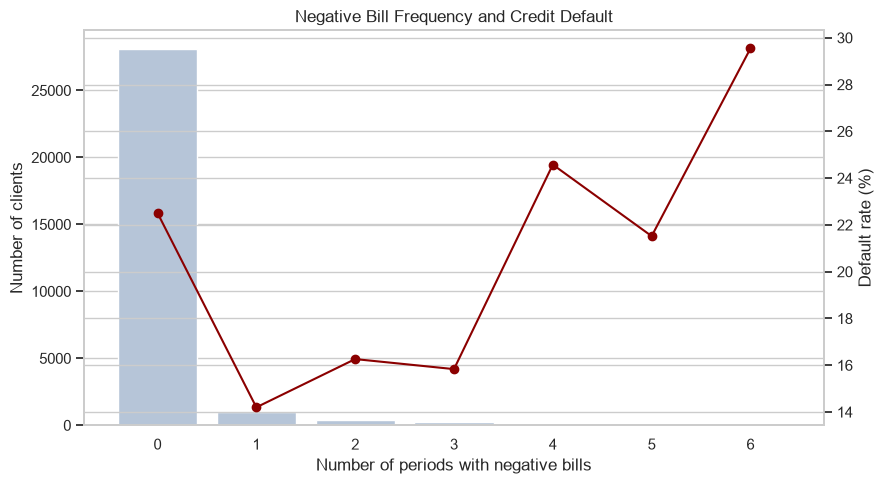

In [10]:
fig, ax1 = plt.subplots(figsize=(9, 5))

# Number of clients
sns.barplot(
    data=result.reset_index(),
    x="NEGATIVE_BILL_COUNT",
    y="number_of_clients",
    color="lightsteelblue",
    ax=ax1
)

ax1.set_xlabel("Number of periods with negative bills")
ax1.set_ylabel("Number of clients")
ax1.set_title("Negative Bill Frequency and Credit Default")

# Default rate on secondary axis
ax2 = ax1.twinx()

ax2.plot(
    range(len(result)),
    result["default_rate"],
    marker="o",
    color="darkred"
)

ax2.set_ylabel("Default rate (%)")

plt.tight_layout()
plt.show()

Há três pontos importantes:
1. A maioria esmagadora dos clientes não teve nenhuma fatura negativa: 28.070 dos 30.000 clientes.
2. Entre os clientes com 1 a 3 períodos negativos, a taxa de default ficou abaixo dos 22,51% observados no grupo sem faturas negativas.
3. Nos grupos com 4 a 6 períodos, a taxa volta a subir, mas temos poucos clientes. O grupo de seis períodos, por exemplo, contém apenas 88 observações.
Um cuidado com a visualização: como o grupo zero é muito maior, as barras dos demais grupos ficam praticamente invisíveis. Isso dificulta comparar suas quantidades.

Eu manteria esse gráfico como registro exploratório, mas não tiraria conclusões fortes sobre os grupos menores.